In [1]:
## tools

from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper,ArxivAPIWrapper

/Volumes/Mathura SSD/Projets/Agentic-AI-Langgraph/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
api_wrapper_arxiv=ArxivAPIWrapper(top_k_results=2,doc_content_chars_max=500)
arxiv=ArxivQueryRun(api_wrapper=api_wrapper_arxiv,description="Query arxiv papers")
print(arxiv.name)

arxiv


In [3]:
arxiv.invoke("Attention is all you need")

'Published: 2021-05-06\nTitle: Do You Even Need Attention? A Stack of Feed-Forward Layers Does Surprisingly Well on ImageNet\nAuthors: Luke Melas-Kyriazi\nSummary: The strong performance of vision transformers on image classification and other vision tasks is often attributed to the design of their multi-head attention layers. However, the extent to which attention is responsible for this strong performance remains unclear. In this short report, we ask: is the attention layer even necessary? Specifi'

In [4]:
api_wrapper_wiki=WikipediaAPIWrapper(top_k_results=1, doc_content_chars_max=500)
wiki=WikipediaQueryRun(api_wrapper=api_wrapper_wiki)
wiki.name

'wikipedia'

In [5]:
wiki.invoke("Attention is all you need")

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [6]:
# integrate tools in workflow
from dotenv import load_dotenv
load_dotenv()

import os

os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

In [7]:
# tavily search tool
from langchain_community.tools.tavily_search import TavilySearchResults

tavily = TavilySearchResults()

/var/folders/sy/l78029ys4fn21j0ftgwj4tzw0000gn/T/ipykernel_24960/4203881020.py:4: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-tavily package and should be used instead. To use it run `pip install -U :class:`~langchain-tavily` and import as `from :class:`~langchain_tavily import TavilySearch``.
  tavily = TavilySearchResults()


In [8]:
tavily.invoke("Provide me the recent AI new ?s")

[{'title': 'The Latest AI News and Breakthroughs That Matter Most',
  'url': 'https://www.crescendo.ai/news/latest-ai-news-and-updates',
  'content': "Date: July 2, 2026\n\nSummary: Anthropic is in early discussions with Samsung to develop a custom AI chip, joining competitors seeking to reduce reliance on Nvidia. The move follows OpenAI's announcement of its own custom inference processor built with Broadcom. Multiple AI companies now pursue specialized silicon to optimize performance and address compute constraints.\n\nSource: TechCrunch\n\n### (AI Update) New York Enacts First-of-Its-Kind Law Requiring AI-Generated Ad Disclosures\n\nDate: July 2, 2026 [...] Source: Washington Post\n\n### (AI Controversy) Google Files AI Phishing Lawsuit in New York\n\nDate: June 12, 2026\n\nSummary: Google filed a major New York lawsuit against operators of an AI-powered phishing scheme that used artificial intelligence to impersonate businesses and deceive users into sharing sensitive information. 

In [9]:
## combine all these tools in the list
tools=[arxiv, wiki, tavily]

In [10]:
## Initialize the LLM model
from langchain_groq import ChatGroq

llm = ChatGroq(model = "qwen/qwen3.8-27b")

In [11]:
llm.invoke("What is AI ?")

AIMessage(content='**AI**, or **Artificial Intelligence**, is a branch of computer science focused on building systems capable of performing tasks that typically require human intelligence.\n\n### Core Components of AI\nAI is primarily achieved through two major methods:\n\n1. **Machine Learning (ML)**:  \n   - A subset of AI where computers learn from data rather than being explicitly programmed.  \n   - It identifies patterns and makes predictions or decisions based on input data.\n\n2. **Deep Learning**:  \n   - A specialized form of ML using **neural networks** with many layers (hence "deep").  \n   - It excels at complex tasks like image recognition, natural language processing, and speech recognition.\n\n### Key Capabilities of AI\n- **Natural Language Processing (NLP)**: Understanding and generating human language (e.g., chatbots, translation tools).\n- **Computer Vision**: Interpreting visual information from the world (e.g., facial recognition, autonomous vehicles).\n- **Decis

In [12]:
## Combine with our llm
llm_with_tools= llm.bind_tools(tools=tools)

In [13]:
## Execute this call
llm_with_tools.invoke("What is the recent news on AI ?")

AIMessage(content="I don't have access to real-time information, so I can't provide specific recent news about AI. My knowledge has a training cutoff, and I cannot browse the internet or access current events.\n\nTo get the latest news on AI, I'd recommend checking:\n\n1. **Tech news websites** like TechCrunch, The Verge, Ars Technica\n2. **AI-specific publications** like The Batch (by Andrew Ng), MIT Technology Review's AI section\n3. **News aggregators** like Google News\n4. **Social media** platforms where AI researchers and companies announce updates\n5. **Company blogs** from major AI players like OpenAI, Google DeepMind, Anthropic, etc.\n\nIs there a specific aspect of AI you're interested in? I can share what I know up to my knowledge cutoff, or help you think about how to find the most current information on a particular topic.", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 188, 'prompt_tokens': 478, 'total_tokens': 666, 'completion_time': 0.403

In [14]:
llm_with_tools.invoke("What is the latest research on quantum computing ?")

AIMessage(content='To provide you with the most current and accurate information, I will search for the latest research developments in quantum computing.\n\n', additional_kwargs={'tool_calls': [{'id': '4k5z4s8m6', 'function': {'arguments': '{"query":"latest research breakthroughs quantum computing 2024 2025"}', 'name': 'tavily_search_results_json'}, 'type': 'function'}, {'id': 'awm38643e', 'function': {'arguments': '{"query":"quantum computing recent advances 2024"}', 'name': 'arxiv'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 103, 'prompt_tokens': 479, 'total_tokens': 582, 'completion_time': 0.312770994, 'completion_tokens_details': None, 'prompt_time': 0.041020805, 'prompt_tokens_details': None, 'queue_time': 0.018172127, 'total_time': 0.353791799}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_43dd1ea4ee', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None}, id='run--01a0d569-2a23-7062-82dc-8a285ac7f6e1-0'

In [15]:
llm_with_tools.invoke("What is machine learning ?")

AIMessage(content='Machine learning (ML) is a subfield of **artificial intelligence (AI)** that focuses on building systems that can **learn from data** and improve their performance on a task over time, without being explicitly programmed for every rule.\n\n### Core Idea\nInstead of writing explicit instructions for every possible scenario, you provide the algorithm with:\n1. **Data** (examples, observations, or past experience)\n2. **A learning objective** (what it should predict, classify, or optimize)\n\nThe algorithm then discovers patterns and relationships in the data to make predictions or decisions on new, unseen data.\n\n### Key Types of Machine Learning\n\n| Type | Description | Example |\n|------|-------------|---------|\n| **Supervised Learning** | Learns from labeled data (input → known output) | Spam email detection, house price prediction |\n| **Unsupervised Learning** | Finds hidden patterns in unlabeled data | Customer segmentation, anomaly detection |\n| **Reinforcem

## Workflow

In [16]:
# State Schema
from typing_extensions import TypedDict ## for the entire state
from langchain_core.messages import AnyMessage ## human message or AI message
from typing import Annotated ## labelling
from langgraph.graph.message import add_messages ## Reducers and langgraph

/Volumes/Mathura SSD/Projets/Agentic-AI-Langgraph/venv/lib/python3.9/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


In [17]:
## define state schema (key variable that will be passing through all the nodes)
class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

In [18]:
## Entire Chatbot with Langgraph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langchain_core.messages import HumanMessage

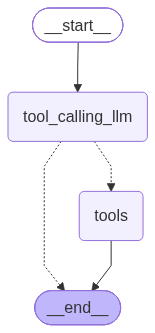

In [ ]:
## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # if the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # if the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
messages=graph.invoke({"messages":HumanMessage(content="1706.03762")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

1706.03762
================================== Ai Message ==================================
Tool Calls:
  arxiv (2amasx1z6)
 Call ID: 2amasx1z6
  Args:
    query: 1706.03762
================================= Tool Message =================================
Name: arxiv

Published: 2023-08-02
Title: Attention Is All You Need
Authors: Ashish Vaswani, Noam Shazeer, Niki Parmar, Jakob Uszkoreit, Llion Jones, Aidan N. Gomez, Lukasz Kaiser, Illia Polosukhin
Summary: The dominant sequence transduction models are based on complex recurrent or convolutional neural networks in an encoder-decoder configuration. The best performing models also connect the encoder and decoder through an attention mechanism. We propose a new simple network architecture, the Transformer, base


In [ ]:
messages=graph.invoke({"messages":"Hi, my name is Mathura"})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Hi, my name is Mathura
================================== Ai Message ==================================

Hi Mathura! Nice to meet you. How can I help you today?


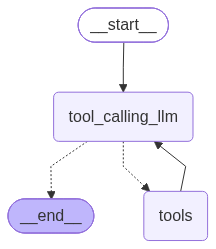

In [20]:
## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # if the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # if the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [28]:
# Invoke the graph
messages = graph.invoke({"messages": "What is the recent AI news and please tell me the recent research paper on quantum computing ?"})

for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent AI news and please tell me the recent research paper on quantum computing ?
================================== Ai Message ==================================

I'll search for recent AI news and recent quantum computing research papers for you.
Tool Calls:
  tavily_search_results_json (0meyryj7g)
 Call ID: 0meyryj7g
  Args:
    query: latest AI news 2025
  arxiv (y40wvyn8s)
 Call ID: y40wvyn8s
  Args:
    query: quantum computing recent advances
================================= Tool Message =================================
Name: tavily_search_results_json

[{"title": "AI NEWS: The Next Wave of AI Tools Is Here", "url": "https://www.youtube.com/watch?v=IxSHA64vc2o&vl=en-US", "content": "# AI NEWS: The Next Wave of AI Tools Is Here\n## Matt Wolfe\n998000 subscribers\n3116 likes\n\n### Description\n91561 views\nPosted: 1 Nov 2025\n#ainews #mattwolfe #openai \nA breakdown of the AI news fro

## Chatbot with Tools

In [2]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")


ModuleNotFoundError: No module named 'langchain_tavily'